# 34 · What does the weighting change?

The synthetic study separates gradient weighting, orientation phase, and damping. It starts with a two-population calculation, then measures axis error on crossed ramps and top-1 retrieval on separate galleries.

**Result.** Keeping phase improved same-orientation retrieval by 20.66 percentage points under linear weighting and 17.88 under quadratic weighting. With phase and damping, the two weightings were within 0.18 points of each other. Damping strongly improved retrieval even though the local axis was identical.

In [1]:
from pathlib import Path
import sys
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage10 import edge
R = ROOT/'results'/'stage10'/'synthetic'


## 1. Two gradient populations

For two separate groups of equal sample count, orient the first at $0$ and the second at $\phi$. If the second group has $r$ times the first group's gradient magnitude, the undamped field is $(1+r^p e^{2i\phi})/(1+r^p)$. At $\phi=45°$ and $r=0.5$, the axis is $\tfrac12\arctan(r^p)$. At $\phi=90°$ and $r=1$ the field vanishes. In an image, gradients add as vectors where two ramps overlap, so the rendered experiment tests a distinct case.

In [3]:
orders = np.array([1, 2])
q = (1 + .5**orders * 1j)/(1 + .5**orders)
display(pd.DataFrame({'p': orders, 'axis error (degrees)': np.degrees(np.angle(q))/2}))
assert abs(1 + np.exp(2j*np.pi/2)) < 1e-12


,p,axis error (degrees)
0,1,13.282526
1,2,7.018122


## 2. Rendered crossing edges

At each condition, average the center-pixel axial error over the same 160 base angles and noise draws. The primary edge defines the target axis. A crossing stronger than the target remains nuisance by design. The plots show the noise-free and highest-noise cases. The saved data also include the intermediate noise level.

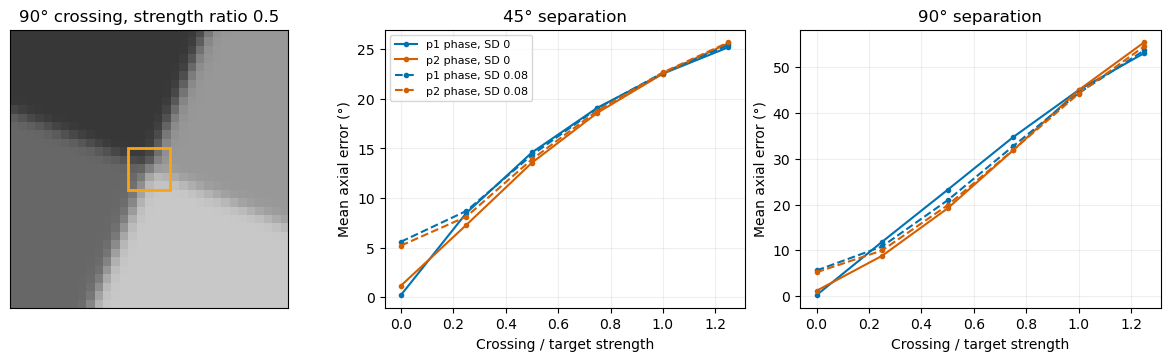

In [5]:
trials = pd.read_csv(R/'angle_trials.csv.gz')
assert len(trials) == 160 * 2 * 6 * 3 * 4
keys = ['trial', 'separation_deg', 'ratio', 'noise_sd']
for name in ('p1 phase', 'p2 phase'):
    a = trials.query('method == @name').set_index(keys)
    b = trials[trials.method == f"{name} no floor"].set_index(keys)
    np.testing.assert_allclose(a.axis_error_deg, b.axis_error_deg, atol=1e-10, equal_nan=True)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout='constrained')
scene = .5 + .19*(edge(np.pi/8) + .5*edge(np.pi/8 + np.pi/2))
axes[0].imshow(scene, cmap='gray', vmin=0, vmax=1)
axes[0].add_patch(plt.Rectangle((13.5, 13.5), 5, 5, fill=False, edgecolor='#fca311', linewidth=2))
axes[0].set(title='90° crossing, strength ratio 0.5', xticks=[], yticks=[])
for ax, separation in zip(axes[1:], (45, 90)):
    for sd, style in ((0., '-'), (.08, '--')):
        for method, color in (('p1 phase', '#0072b2'), ('p2 phase', '#d55e00')):
            subset = trials.query('separation_deg == @separation and noise_sd == @sd and method == @method')
            means = subset.groupby('ratio').axis_error_deg.mean()
            ax.plot(means.index, means, style, marker='o', ms=3, color=color, label=f'{method}, SD {sd:g}')
    ax.set(title=f'{separation}° separation', xlabel='Crossing / target strength', ylabel='Mean axial error (°)')
    ax.grid(alpha=.2)
axes[1].legend(fontsize=8, loc='upper left')
fig.savefig(R/'34_crossing_axis_error.png', dpi=160)
plt.show()


At a clean 90° crossing with strength ratio 0.5, quadratic weighting reduced mean axis error from 23.21° to 19.16°. When the nuisance edge became stronger than the target (ratio 1.25), quadratic weighting increased error from 53.08° to 55.44°. The floor leaves these axes unchanged.

## 3. Retrieval with separate galleries

Twelve galleries of 24 edges vary position, width, and strength within each of six orientations. Each image supplies four corrupted queries. Same-orientation top-1 removes the original and has three correct targets among 23. Damped and undamped variants share the gallery, query, and search budget.

,identity,class
method,,
aligned ZNCC,42.53,91.67
aligned pixels,41.32,81.08
p1 magnitude,14.24,60.85
p1 magnitude no floor,6.16,17.27
p1 phase,30.38,81.51
p1 phase no floor,11.41,38.28
p2 magnitude,25.00,63.45
p2 magnitude no floor,11.28,25.00
p2 phase,35.33,81.34


,difference,low95,high95
contrast,,,
p1 phase gain,20.66,18.40,23.00
p2 phase gain,17.88,15.80,19.97
p1 minus p2 phase,0.17,-1.22,1.65
phase-gain interaction,2.78,0.35,5.21
p1 phase floor effect,43.23,40.62,45.49
p1 magnitude floor effect,43.58,41.58,45.92
p2 phase floor effect,31.60,29.34,33.85
p2 magnitude floor effect,38.45,34.29,42.01


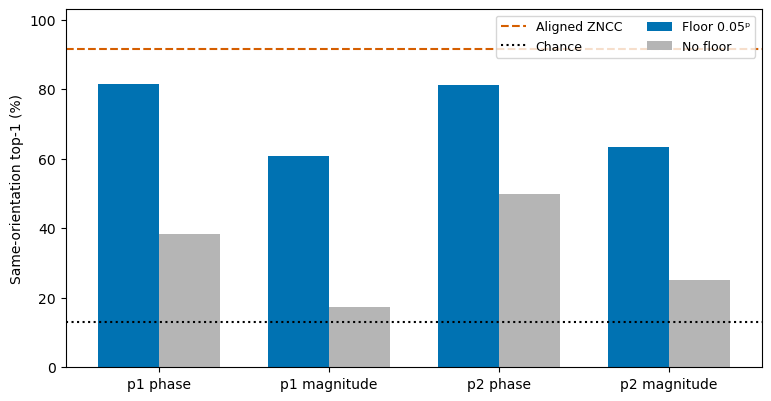

In [7]:
summary = pd.read_csv(R/'summary.csv').set_index('method')[['identity', 'class']]
contrasts = pd.read_csv(R/'contrasts.csv')
display((100 * summary).round(2))
show = contrasts.query('endpoint == "class"').drop(columns=['panel', 'endpoint']).set_index('contrast')
display((100 * show).round(2))

names = ['p1 phase', 'p1 magnitude', 'p2 phase', 'p2 magnitude']
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(7.6, 3.9), layout='constrained')
ax.bar(x-.18, summary.loc[names, 'class']*100, .36, label='Floor 0.05ᵖ', color='#0072b2')
ax.bar(x+.18, summary.loc[[f'{name} no floor' for name in names], 'class']*100, .36,
       label='No floor', color='#b5b5b5')
ax.axhline(100*summary.loc['aligned ZNCC', 'class'], color='#d55e00', linestyle='--', label='Aligned ZNCC')
ax.axhline(300/23, color='black', linestyle=':', label='Chance')
ax.set(xticks=x, xticklabels=names, ylabel='Same-orientation top-1 (%)', ylim=(0, 103))
ax.legend(ncols=2, fontsize=9)
fig.savefig(R/'34_synthetic_retrieval.png', dpi=160)
plt.show()


Aligned ZNCC reached 91.67% on this synthetic category task, ahead of both phase fields. The floor is consequential here because undamped weak-gradient windows can acquire high apparent order even from tiny fluctuations. The bootstrap intervals pair whole galleries and apply to this construction.